# Unidad II · Actividad de Evaluación 1
## Exploración, clasificación y diagnóstico del conjunto de datos

| | |
|---|---|
| **Alumno** | Jorge Alberto Rodríguez Enríquez — 9 IDGS G1, UTTT |
| **Asignatura** | Extracción de Conocimiento en Bases de Datos (Recursamiento 2026) |
| **Docente** | Ing. José Luis Herrera Gallardo, MTI |
| **Proyecto** | Estimación de edad y análisis morfológico de abulones |
| **Dataset** | Abalone — UCI Machine Learning Repository |
| **Fase CRISP-DM** | 2. Comprensión de los datos |

> ⚠️ **Regla de esta actividad:** el archivo original `data/raw/abalone.data` **solo se lee**. En este notebook **no se elimina ni se modifica ningún dato**; únicamente se explora y se diagnostica.

---
## 1. Identificación del dataset

| Aspecto | Descripción |
|---|---|
| **Proyecto** | Estimación de edad y análisis morfológico de abulones |
| **Dataset** | Abalone |
| **Fuente** | UCI Machine Learning Repository — https://archive.ics.uci.edu/dataset/1/abalone · Nash, W., Sellers, T., Talbot, S., Cawthorn, A., & Ford, W. (1994). https://doi.org/10.24432/C55C7W |
| **Formato** | Archivo de texto plano `abalone.data`, valores separados por comas (CSV) **sin fila de encabezados** |
| **Registros / variables** | 4,177 registros y 9 variables (se comprueba abajo con `df.shape`) |
| **Descripción general** | Cada fila es un abulón (molusco marino) medido en un estudio de Tasmania, Australia. Contiene su sexo, 3 medidas de tamaño, 4 medidas de peso y el número de anillos de su concha (`Rings`), que representa su edad: **edad ≈ Rings + 1.5 años**. |

---
## 2. Carga y exploración inicial

Bibliotecas usadas:
- **pandas** → leer y analizar la tabla (DataFrame).
- **matplotlib** → hacer gráficas.
- **Path** → escribir rutas de carpetas que funcionan en Windows y Linux.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUTA_RAW = Path("..") / "data" / "raw" / "abalone.data"
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_FIG.mkdir(parents=True, exist_ok=True)

# El archivo NO trae encabezados -> header=None y damos los nombres con names=
# Los nombres provienen de la documentación oficial (abalone.names)
COLUMNAS = ["Sex", "Length", "Diameter", "Height", "Whole_weight",
            "Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"]

df = pd.read_csv(RUTA_RAW, header=None, names=COLUMNAS)
print("Archivo cargado desde:", RUTA_RAW)

Archivo cargado desde: ..\data\raw\abalone.data


### 2.1 `df.head()` — primeras filas
Muestra las primeras 5 filas para ver cómo lucen los datos.

In [2]:
df.head()

,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


**Interpretación:** cada fila es un abulón. La columna `Sex` contiene letras (M, F, I); las columnas de medidas tienen decimales pequeños (por ejemplo 0.455) y `Rings` contiene enteros (15, 7, 9…). Los valores parecen pequeños porque, según la documentación, **las medidas continuas fueron divididas entre 200**: un `Length` de 0.455 equivale a 0.455 × 200 = **91 mm** reales.

### 2.2 `df.shape` — tamaño
Devuelve una tupla **(filas, columnas)**.

In [3]:
print(df.shape)
print(f"Registros: {df.shape[0]:,} | Variables: {df.shape[1]}")

(4177, 9)
Registros: 4,177 | Variables: 9


**Interpretación:** el dataset tiene **4,177 registros y 9 variables**, lo que coincide con la ficha oficial de UCI (4,177 instancias, 8 características + 1 variable objetivo). Confirma que el archivo se leyó completo.

### 2.3 `df.columns` — nombres de las variables

In [4]:
df.columns

Index(['Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight',
       'Viscera_weight', 'Shell_weight', 'Rings'],
      dtype='str')

**Interpretación:** las 9 columnas quedaron con los nombres asignados. Como el archivo original no los traía, sin `names=` pandas habría usado los números 0 a 8 y además habría tomado la primera fila de datos como encabezado, perdiendo un registro.

### 2.4 `df.info()` — resumen técnico
Indica por columna: cantidad de valores **no nulos** y tipo de dato, además de la memoria usada.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole_weight    4177 non-null   float64
 5   Shucked_weight  4177 non-null   float64
 6   Viscera_weight  4177 non-null   float64
 7   Shell_weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 293.8 KB


**Interpretación:** las 9 columnas tienen **4,177 valores no nulos**, es decir, **no hay valores faltantes**. Hay 1 columna de texto (`object`), 7 decimales (`float64`) y 1 entera (`int64`). El dataset ocupa menos de 0.5 MB, por lo que es pequeño y fácil de procesar en una laptop.

### 2.5 `df.dtypes` — tipo de dato de cada columna

In [6]:
df.dtypes

Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole_weight      float64
Shucked_weight    float64
Viscera_weight    float64
Shell_weight      float64
Rings               int64
dtype: object

**Interpretación:**
- `Sex` → **object** (texto): es una categoría; habrá que convertirla a números (codificación *one-hot*) antes de usarla en modelos.
- `Length` … `Shell_weight` → **float64**: medidas continuas con decimales. Correcto.
- `Rings` → **int64**: conteo de anillos, número entero. Correcto.

Los tipos son coherentes con lo que representa cada variable; **no hay columnas numéricas guardadas como texto por error**.

### 2.6 `df.describe()` — estadística descriptiva
Para cada variable numérica: conteo, media (*mean*), desviación estándar (*std*), mínimo, cuartiles (25%, 50% = mediana, 75%) y máximo.

In [7]:
df.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.524,0.120,0.075,0.450,0.545,0.615,0.815
Diameter,4177.0,0.408,0.099,0.055,0.350,0.425,0.480,0.650
Height,4177.0,0.140,0.042,0.000,0.115,0.140,0.165,1.130
Whole_weight,4177.0,0.829,0.490,0.002,0.442,0.800,1.153,2.826
Shucked_weight,4177.0,0.359,0.222,0.001,0.186,0.336,0.502,1.488
Viscera_weight,4177.0,0.181,0.110,0.000,0.094,0.171,0.253,0.760
Shell_weight,4177.0,0.239,0.139,0.002,0.130,0.234,0.329,1.005
Rings,4177.0,9.934,3.224,1.000,8.000,9.000,11.000,29.000


**Interpretación:**
- Todas las variables tienen 4,177 datos (sin faltantes).
- **⚠️ `Height` tiene mínimo 0**: un abulón no puede medir 0 de altura → **error de captura**.
- **⚠️ `Height` tiene máximo 1.13**, cuando el 75% de los datos está por debajo de 0.165 → valor sospechosamente extremo.
- `Rings` va de **1 a 29**, con media 9.93 y mediana 9: la mayoría de los abulones tiene entre 8 y 11 anillos (≈ 9.5 a 12.5 años).
- En los pesos la media es algo mayor que la mediana → hay algunos ejemplares muy pesados que "jalan" el promedio hacia arriba (sesgo a la derecha).

---
## 3. Diccionario de datos

Se construye como un DataFrame para poder verlo, guardarlo e incluirlo en el informe. El tipo de dato en Python se toma directamente de `df.dtypes`.

In [8]:
info = {
 "Sex":            ("Sexo del abulón: M = macho, F = hembra, I = infante (cría)", "Cualitativa", "Nominal", "—",
                    "Predictora en regresión/clasificación; permite comparar grupos"),
 "Length":         ("Medida más larga de la concha", "Cuantitativa", "Continua", "mm (÷200)",
                    "Predictora de la edad; variable para clustering"),
 "Diameter":       ("Medida perpendicular al largo (ancho)", "Cuantitativa", "Continua", "mm (÷200)",
                    "Predictora de la edad; variable para clustering"),
 "Height":         ("Altura con la carne dentro de la concha", "Cuantitativa", "Continua", "mm (÷200)",
                    "Predictora; requiere revisión (ceros y extremos)"),
 "Whole_weight":   ("Peso del abulón completo", "Cuantitativa", "Continua", "g (÷200)",
                    "Predictora de la edad; variable para clustering"),
 "Shucked_weight": ("Peso de la carne", "Cuantitativa", "Continua", "g (÷200)",
                    "Predictora; valor comercial del ejemplar"),
 "Viscera_weight": ("Peso de las vísceras (después de desangrar)", "Cuantitativa", "Continua", "g (÷200)",
                    "Predictora de la edad"),
 "Shell_weight":   ("Peso de la concha seca", "Cuantitativa", "Continua", "g (÷200)",
                    "Predictora más relacionada con la edad"),
 "Rings":          ("Número de anillos de la concha; edad ≈ Rings + 1.5 años", "Cuantitativa", "Discreta", "anillos",
                    "Variable objetivo de regresión; base para crear el grupo de edad"),
}

diccionario = pd.DataFrame([
    {"Variable": col, "Descripción": d, "Tipo Python": str(df[col].dtype), "Tipo de variable": t,
     "Clasificación": c, "Unidad": u, "Posible utilidad": p}
    for col, (d, t, c, u, p) in info.items()
])
diccionario

,Variable,Descripción,Tipo Python,Tipo de variable,Clasificación,Unidad,Posible utilidad
0,Sex,"Sexo del abulón: M = macho, F = hembra, I = in...",str,Cualitativa,Nominal,—,Predictora en regresión/clasificación; permite...
1,Length,Medida más larga de la concha,float64,Cuantitativa,Continua,mm (÷200),Predictora de la edad; variable para clustering
2,Diameter,Medida perpendicular al largo (ancho),float64,Cuantitativa,Continua,mm (÷200),Predictora de la edad; variable para clustering
3,Height,Altura con la carne dentro de la concha,float64,Cuantitativa,Continua,mm (÷200),Predictora; requiere revisión (ceros y extremos)
4,Whole_weight,Peso del abulón completo,float64,Cuantitativa,Continua,g (÷200),Predictora de la edad; variable para clustering
5,Shucked_weight,Peso de la carne,float64,Cuantitativa,Continua,g (÷200),Predictora; valor comercial del ejemplar
6,Viscera_weight,Peso de las vísceras (después de desangrar),float64,Cuantitativa,Continua,g (÷200),Predictora de la edad
7,Shell_weight,Peso de la concha seca,float64,Cuantitativa,Continua,g (÷200),Predictora más relacionada con la edad
8,Rings,Número de anillos de la concha; edad ≈ Rings +...,int64,Cuantitativa,Discreta,anillos,Variable objetivo de regresión; base para crea...


**Interpretación:** el dataset tiene **1 variable cualitativa nominal** (`Sex`, sus categorías no tienen orden), **7 cuantitativas continuas** (medidas que pueden tomar cualquier valor decimal) y **1 cuantitativa discreta** (`Rings`, solo toma valores enteros porque es un conteo). La unidad "÷200" recuerda que los valores están escalados.

---
## 4. Tipo y fuente de los datos

- **Procedencia:** estudio biológico del Departamento de Industria Primaria y Pesca de Tasmania (Nash et al., 1994), publicado y mantenido por el UCI Machine Learning Repository.
- **Tipo de datos:** **datos generados por personas** (mediciones manuales). Investigadores midieron con instrumentos (vernier y báscula) cada abulón y contaron sus anillos al microscopio. No son transacciones, ni datos web o de redes sociales, ni lecturas automáticas de sensores; tampoco son biométricos humanos.
- **Clasificación de la fuente:** **estructurada**. Es una tabla con filas y columnas fijas, el mismo número de campos en cada registro y un tipo de dato definido por columna; puede cargarse directamente en pandas o en una base de datos relacional (SQL Server).

---
## 5. Diagnóstico de calidad
### 5.1 Valores faltantes — `df.isnull().sum()`
`isnull()` marca con `True` cada celda vacía y `.sum()` las cuenta por columna.

In [9]:
faltantes = pd.DataFrame({
    "Faltantes": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2),
})
faltantes

,Faltantes,Porcentaje (%)
Sex,0,0.0
Length,0,0.0
Diameter,0,0.0
Height,0,0.0
Whole_weight,0,0.0
Shucked_weight,0,0.0
Viscera_weight,0,0.0
Shell_weight,0,0.0
Rings,0,0.0


**Interpretación:** **no existe ningún valor faltante** (0 en todas las variables, 0%). La documentación de UCI indica que los registros con datos faltantes se eliminaron en el estudio original.

**Tratamiento propuesto para la siguiente etapa:** no se requiere imputación. Aun así, el proceso ETL incluirá una validación automática (`assert df.isnull().sum().sum() == 0`) para garantizar que siga sin faltantes después de las transformaciones.

### 5.2 Registros duplicados — `df.duplicated().sum()`
`duplicated()` marca las filas que son idénticas a una fila anterior en **todas** sus columnas.

In [10]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


**Interpretación:** **no hay registros duplicados.** Si los hubiera, una causa posible sería capturar dos veces el mismo abulón o unir dos archivos con información repetida.

**Tratamiento propuesto:** no aplica eliminar duplicados. Como el dataset no tiene un identificador propio, en la etapa de ETL se agregará una columna `ID_Abulon` para que cada registro sea único y pueda usarse como llave primaria en el Data Mart.

### 5.3 Valores incorrectos o inconsistentes
Se revisan reglas lógicas que **todo abulón real debe cumplir**:

In [11]:
reglas = {
    "Sex con categoría distinta de M/F/I":         ~df["Sex"].isin(["M", "F", "I"]),
    "Medidas negativas":                           (df[COLUMNAS[1:]] < 0).any(axis=1),
    "Altura igual a 0":                            df["Height"] == 0,
    "Altura extrema (> 0.3)":                      df["Height"] > 0.3,
    "Diámetro mayor que el largo":                 df["Diameter"] > df["Length"],
    "Peso de la carne > peso total":               df["Shucked_weight"] > df["Whole_weight"],
    "Peso de la concha > peso total":              df["Shell_weight"] > df["Whole_weight"],
    "Suma carne + vísceras + concha > peso total": (df["Shucked_weight"] + df["Viscera_weight"]
                                                    + df["Shell_weight"]) > df["Whole_weight"],
}
inconsistencias = pd.DataFrame({"Registros": {k: int(v.sum()) for k, v in reglas.items()}})
inconsistencias

,Registros
Sex con categoría distinta de M/F/I,0
Medidas negativas,0
Altura igual a 0,2
Altura extrema (> 0.3),2
Diámetro mayor que el largo,1
Peso de la carne > peso total,4
Peso de la concha > peso total,1
Suma carne + vísceras + concha > peso total,155


In [12]:
print("Categorías de Sex:", sorted(df["Sex"].unique()))
print("\nRegistros con altura 0 o extrema:")
print(df[(df["Height"] == 0) | (df["Height"] > 0.3)])

Categorías de Sex: ['F', 'I', 'M']

Registros con altura 0 o extrema:
     Sex  Length  Diameter  Height  Whole_weight  Shucked_weight  \
1257   I   0.430     0.340   0.000         0.428          0.2065   
1417   M   0.705     0.565   0.515         2.210          1.1075   
2051   F   0.455     0.355   1.130         0.594          0.3320   
3996   I   0.315     0.230   0.000         0.134          0.0575   

      Viscera_weight  Shell_weight  Rings  
1257          0.0860        0.1150      8  
1417          0.4865        0.5120     10  
2051          0.1160        0.1335      8  
3996          0.0285        0.3505      6  


**Interpretación:**
| Problema | Registros | ¿Error? | Tratamiento propuesto (etapa de limpieza) |
|---|---|---|---|
| Categorías de `Sex` | 0 | — | Solo existen M, F e I: **sin inconsistencias**. Se traducirán a Macho/Hembra/Infante para el dashboard. |
| Valores negativos | 0 | — | Ninguno. |
| Altura = 0 | 2 | **Sí**, imposible | Eliminar. |
| Altura > 0.3 (0.515 y 1.13) | 2 | **Muy probable**: equivalen a 103 y 226 mm, cuando el resto no pasa de 50 mm | Eliminar. |
| Diámetro > largo | 1 | **Sí**: por definición el largo es la medida mayor | Eliminar o revisar. |
| Carne o concha pesan más que el abulón completo | 4 + 1 | **Sí**, imposible | Eliminar. |
| Suma de partes > peso total | 155 | **No necesariamente**: las partes se pesan por separado (la carne húmeda, la concha seca) y el abulón pierde agua y sangre al abrirse | Conservar y documentar. |

En total, menos de 10 registros (≈ 0.2% del dataset) son **físicamente imposibles**. El nivel de calidad es alto.

---
## 6. Análisis estadístico inicial
Se seleccionan las variables más relevantes para el problema: la **edad** (`Rings`), la variable más relacionada con ella (`Shell_weight`) y dos medidas de tamaño (`Length` y `Height`).

In [13]:
VARS = ["Rings", "Shell_weight", "Length", "Height"]
estad = pd.DataFrame({
    "Media": df[VARS].mean(),
    "Mediana": df[VARS].median(),
    "Mínimo": df[VARS].min(),
    "Máximo": df[VARS].max(),
    "Desv. estándar": df[VARS].std(),
}).round(3)
estad

,Media,Mediana,Mínimo,Máximo,Desv. estándar
Rings,9.934,9.000,1.000,29.000,3.224
Shell_weight,0.239,0.234,0.002,1.005,0.139
Length,0.524,0.545,0.075,0.815,0.120
Height,0.140,0.140,0.000,1.130,0.042


In [14]:
# Las mismas medidas en unidades reales (× 200) para interpretarlas mejor
reales = (estad.loc[["Shell_weight", "Length", "Height"]] * 200).round(1)
reales.index = ["Shell_weight (g)", "Length (mm)", "Height (mm)"]
reales

,Media,Mediana,Mínimo,Máximo,Desv. estándar
Shell_weight (g),47.8,46.8,0.4,201.0,27.8
Length (mm),104.8,109.0,15.0,163.0,24.0
Height (mm),28.0,28.0,0.0,226.0,8.4


**Interpretación en relación con el proyecto:**
- **Rings:** media 9.93 y mediana 9 → la edad típica es de **≈ 10.5 a 11.5 años**. La desviación de 3.2 anillos indica una variación moderada; el máximo de 29 anillos (≈ 30 años) es raro, pero biológicamente posible.
- **Shell_weight:** media ≈ 48 g y mediana ≈ 47 g reales, con mínimo de apenas 0.4 g (crías muy pequeñas) y máximo ≈ 201 g.
- **Length:** media ≈ 105 mm reales; la mediana (109 mm) es mayor que la media → hay una "cola" de ejemplares pequeños (infantes).
- **Height:** media ≈ 28 mm, pero su máximo de 226 mm y su mínimo de 0 confirman los **errores de captura** detectados en la sección 5.3.

Que haya mucha variación en tamaño y peso es positivo: significa que esas medidas pueden ayudar a **distinguir abulones de distintas edades**.

---
## 7. Detección inicial de valores atípicos

Se usan **diagramas de caja (boxplot)** y la **regla IQR**: un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR, donde IQR = Q3 − Q1 (el 50% central de los datos).

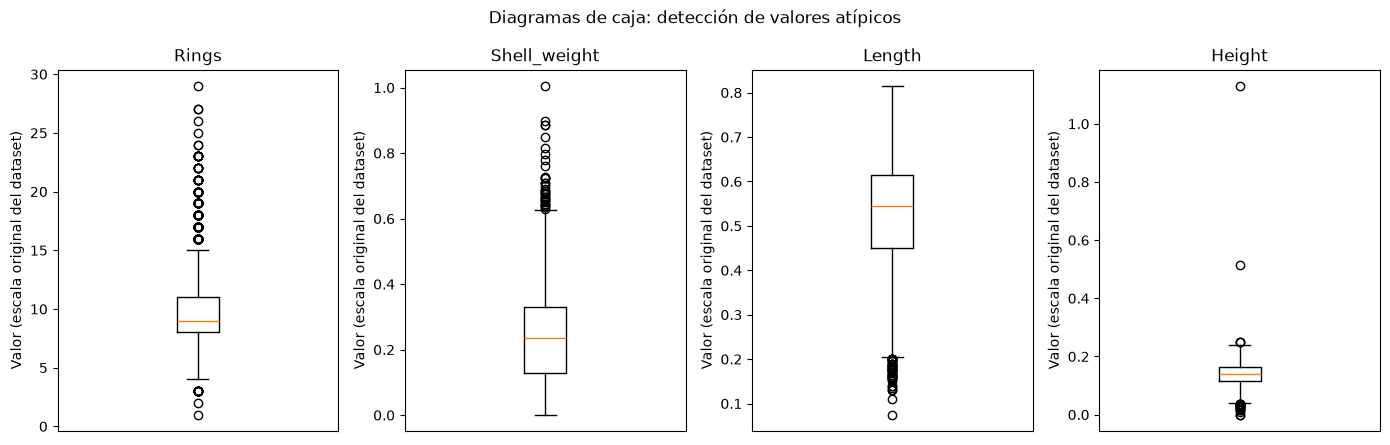

In [15]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 4.5))
for ax, col in zip(ejes, VARS):
    ax.boxplot(df[col])
    ax.set_title(col)
    ax.set_xticks([])
    ax.set_ylabel("Valor (escala original del dataset)")
fig.suptitle("Diagramas de caja: detección de valores atípicos")
plt.tight_layout()
plt.savefig(RUTA_FIG / "ae1_boxplots.png", dpi=130)
plt.show()

In [16]:
atipicos = []
for col in VARS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    atipicos.append({"Variable": col, "Límite inferior": round(lim_inf, 3),
                     "Límite superior": round(lim_sup, 3), "Atípicos": int(n),
                     "% del total": round(n / len(df) * 100, 1)})
pd.DataFrame(atipicos)

,Variable,Límite inferior,Límite superior,Atípicos,% del total
0,Rings,3.500,15.500,278,6.7
1,Shell_weight,-0.168,0.627,35,0.8
2,Length,0.203,0.862,49,1.2
3,Height,0.040,0.240,29,0.7


**Interpretación de cada caso:**
| Variable | Comportamiento | ¿Válido o error? | Tratamiento propuesto |
|---|---|---|---|
| **Rings** | 278 atípicos: abulones con ≤ 3 o ≥ 16 anillos | **Válidos**: son ejemplares muy jóvenes o muy viejos, que existen pero son menos frecuentes | **Conservar**. Eliminarlos haría que el modelo no aprendiera a reconocer abulones viejos. |
| **Shell_weight** | 35 atípicos, todos por arriba | **Válidos**: abulones grandes y pesados | **Conservar**. |
| **Length** | 49 atípicos, todos por abajo | **Válidos**: crías (infantes) muy pequeñas | **Conservar**. |
| **Height** | 29 atípicos; 2 en cero y 2 extremadamente altos (se ven aislados en la gráfica) | Los ceros y los 2 extremos son **errores**; el resto son ejemplares pequeños o grandes reales | **Eliminar solo los 4 imposibles** y conservar los demás. |

📌 Conclusión: un valor atípico **no es lo mismo que un error**. Solo se eliminarán los valores físicamente imposibles. **En esta actividad no se elimina ninguno.**

---
## 8. Visualización inicial
### 8.1 Gráfica de barras: abulones por sexo

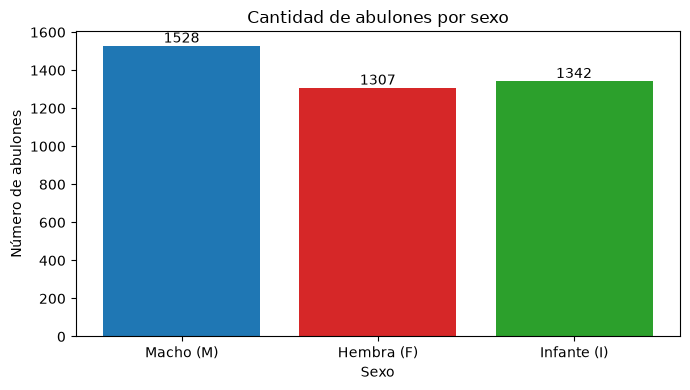

In [17]:
conteo = df["Sex"].value_counts().reindex(["M", "F", "I"])
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(["Macho (M)", "Hembra (F)", "Infante (I)"], conteo.values,
                color=["#1F77B4", "#D62728", "#2CA02C"])
ax.bar_label(barras)
ax.set_title("Cantidad de abulones por sexo")
ax.set_xlabel("Sexo")
ax.set_ylabel("Número de abulones")
plt.tight_layout()
plt.savefig(RUTA_FIG / "ae1_barras_sexo.png", dpi=130)
plt.show()

**Interpretación:** las tres categorías están **equilibradas** (1,528 machos, 1,307 hembras y 1,342 infantes, alrededor de un tercio cada una). Ningún grupo domina el análisis, por lo que las comparaciones entre sexos son confiables.

### 8.2 Histograma: distribución de la edad (Rings)

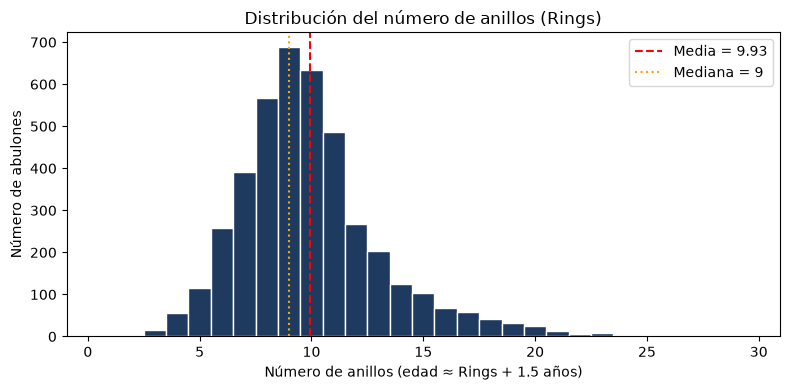

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["Rings"], bins=[x - 0.5 for x in range(1, 31)], color="#1F3A5F", edgecolor="white")
ax.axvline(df["Rings"].mean(), color="red", linestyle="--",
           label=f"Media = {df['Rings'].mean():.2f}")
ax.axvline(df["Rings"].median(), color="orange", linestyle=":",
           label=f"Mediana = {df['Rings'].median():.0f}")
ax.set_title("Distribución del número de anillos (Rings)")
ax.set_xlabel("Número de anillos (edad ≈ Rings + 1.5 años)")
ax.set_ylabel("Número de abulones")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIG / "ae1_hist_rings.png", dpi=130)
plt.show()

**Interpretación:** la mayoría de los abulones tiene entre **7 y 11 anillos**; el valor más frecuente es 9. La distribución tiene una **cola hacia la derecha**: hay pocos ejemplares muy viejos (más de 20 anillos). Esto anticipa que los modelos predecirán mejor las edades intermedias, que tienen más ejemplos, que las edades extremas.

### 8.3 Gráfica de dispersión: peso de la concha vs. anillos

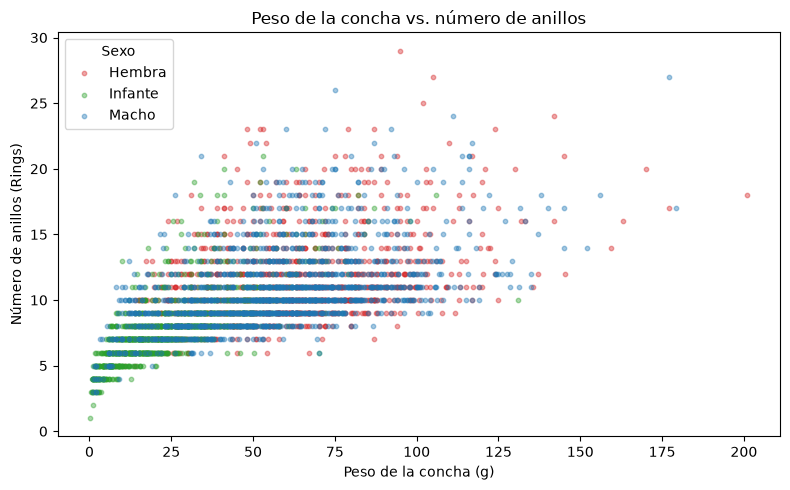

Correlación Shell_weight - Rings: 0.628


In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
colores = {"M": "#1F77B4", "F": "#D62728", "I": "#2CA02C"}
nombres = {"M": "Macho", "F": "Hembra", "I": "Infante"}
for sexo, grupo in df.groupby("Sex"):
    ax.scatter(grupo["Shell_weight"] * 200, grupo["Rings"], s=10, alpha=0.4,
               color=colores[sexo], label=nombres[sexo])
ax.set_title("Peso de la concha vs. número de anillos")
ax.set_xlabel("Peso de la concha (g)")
ax.set_ylabel("Número de anillos (Rings)")
ax.legend(title="Sexo")
plt.tight_layout()
plt.savefig(RUTA_FIG / "ae1_dispersion_concha_rings.png", dpi=130)
plt.show()

print("Correlación Shell_weight - Rings:", round(df["Shell_weight"].corr(df["Rings"]), 3))

**Interpretación:** existe una **relación positiva**: a mayor peso de la concha, más anillos (correlación de 0.63, la más alta del dataset). Los **infantes** (verde) se concentran abajo a la izquierda: son pequeños y jóvenes. La nube se "abre" hacia la derecha: entre los abulones grandes hay mucha variación de edad, porque al llegar a adultos casi dejan de crecer. Por eso estimar la edad de los ejemplares viejos será más difícil.

### 8.4 (Adicional) Mapa de correlación entre variables numéricas

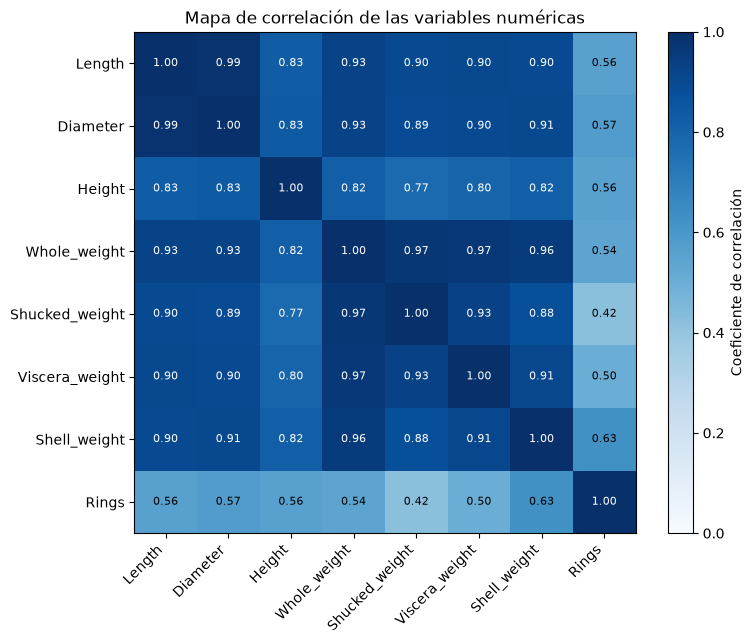

In [20]:
corr = df[COLUMNAS[1:]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.7 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Coeficiente de correlación")
ax.set_title("Mapa de correlación de las variables numéricas")
plt.tight_layout()
plt.savefig(RUTA_FIG / "ae1_correlacion.png", dpi=130)
plt.show()

**Interpretación:** las medidas de tamaño y peso están **muy correlacionadas entre sí** (casi todas > 0.9): un abulón más largo también es más ancho y más pesado. Con `Rings`, las correlaciones son moderadas (0.42 a 0.63). Esto indica que las variables comparten mucha información, lo que justifica usar **PCA** (reducción de dimensionalidad) en la Unidad IV.

---
## 9. Preparación para análisis posteriores

| Análisis | Propuesta | Justificación (problema de la Unidad I) |
|---|---|---|
| **Regresión** | **Objetivo:** `Rings` (numérica discreta). Se intentará predecir **cuántos anillos tiene** un abulón y, con ello, su edad (Rings + 1.5). **Entradas:** `Sex` (codificada), `Length`, `Diameter`, `Height`, `Whole_weight`, `Shucked_weight`, `Viscera_weight` y `Shell_weight`. | El problema es estimar la edad **sin cortar la concha**. Todas las medidas tienen correlación positiva con Rings (0.42–0.63), así que contienen información útil. |
| **Clasificación** | **Objetivo:** nueva variable `Grupo_Edad` derivada de Rings, con 3 clases: **Joven** (Rings ≤ 8), **Adulto** (9–10) y **Maduro** (≥ 11). Cortes basados en los cuartiles de Rings (Q1 = 8, Q3 = 11). | Para un productor o pescador basta saber la **etapa** de crecimiento (por ejemplo, si ya puede cosecharse). Las clases quedan balanceadas (~33% cada una). `Rings` no se usará como entrada para no "dar la respuesta" al modelo. |
| **Agrupamiento** | **Variables:** las 7 medidas físicas (`Length`, `Diameter`, `Height`, `Whole_weight`, `Shucked_weight`, `Viscera_weight`, `Shell_weight`), escaladas. Sin usar `Rings` ni `Sex`. | Se busca descubrir **perfiles morfológicos** naturales (por ejemplo, pequeños, medianos y grandes) y después comparar si coinciden con el sexo o la edad. Como están muy correlacionadas, se aplicará PCA antes o junto con K-Means. |

In [21]:
# Vista previa (sin modificar df): cómo quedarían las clases propuestas
grupos_previos = pd.cut(df["Rings"], bins=[0, 8, 10, 100], labels=["Joven", "Adulto", "Maduro"])
print(grupos_previos.value_counts().reindex(["Joven", "Adulto", "Maduro"]))
print("\n¿Se modificó el DataFrame original?", "Grupo_Edad" in df.columns)

Rings
Joven     1407
Adulto    1323
Maduro    1447
Name: count, dtype: int64

¿Se modificó el DataFrame original? False


**Interpretación:** las tres clases propuestas quedan **balanceadas** (1,407 / 1,323 / 1,447). La variable se calcula aparte para mostrar la propuesta, pero **no se agrega a `df`**; se creará formalmente en la etapa de transformación (ETL).

---
## 10. Conclusión del diagnóstico

1. **¿Qué información contiene el dataset?** Medidas físicas (sexo, 3 dimensiones y 4 pesos) y el número de anillos (edad) de 4,177 abulones de Tasmania.
2. **¿Cuál es su nivel general de calidad?** **Alto**: no tiene faltantes ni duplicados, los tipos de dato son correctos y menos del 0.3% de los registros presenta valores imposibles.
3. **¿Qué problemas fueron identificados?** Alturas iguales a 0 (2), alturas extremas (2), un diámetro mayor que el largo (1) y pesos de partes mayores que el peso total (5). Además, las medidas están escaladas (÷200) y el archivo no trae encabezados.
4. **¿Qué variables requieren tratamiento?** `Height`, `Diameter`/`Length`, `Shucked_weight` y `Shell_weight` (registros imposibles); `Sex` (codificación a números); todas las medidas continuas (escalado para los modelos y conversión a unidades reales para el dashboard).
5. **¿Existen valores faltantes?** **No** (0 en las 9 variables).
6. **¿Existen registros duplicados?** **No** (0).
7. **¿Existen valores atípicos?** **Sí**, según la regla IQR (por ejemplo, 278 en Rings), pero la mayoría son **ejemplares reales** muy jóvenes, viejos o grandes y se conservarán. Solo los valores físicamente imposibles se eliminarán.
8. **¿Qué transformaciones serán necesarias?** Asignar nombres a las columnas, eliminar los registros imposibles, convertir a unidades reales (×200), crear `Edad_anios` y `Grupo_Edad`, codificar `Sex`, escalar las medidas, agregar un identificador y cargar el resultado en `data/processed` y en el Data Mart de SQL Server.
9. **¿Los datos son adecuados para continuar?** **Sí.** El tamaño es suficiente, la calidad es alta y las variables físicas muestran relación con la edad.
10. **¿Qué conocimiento podría obtenerse?** Qué medidas permiten estimar mejor la edad sin sacrificar al animal, con qué precisión puede predecirse, a partir de qué tamaño un abulón se considera adulto y qué perfiles morfológicos existen; información útil para granjas de acuicultura, pescadores y autoridades pesqueras.

In [22]:
# Verificación final: el archivo original sigue intacto
original = pd.read_csv(RUTA_RAW, header=None, names=COLUMNAS)
print("Registros en data/raw:", len(original))
print("¿El DataFrame analizado es idéntico al original?", df.equals(original))

Registros en data/raw: 4177
¿El DataFrame analizado es idéntico al original? True
